# Stage 1 — WP2: Open Models knowledge extraction

This notebook documents a **precision-first, auditable baseline** for entity extraction,
typed relation extraction, and sentence-level entity co-occurrence. It uses the AI Media
Dataset from September 2024 through August 2026 and retains source sentences and offsets
for every extracted assertion.

The pipeline combines a curated Open Models entity catalogue with spaCy statistical NER.
Its `rule_score` is a heuristic ranking score—not a probability or a claim of correctness.
The review sample must be manually labelled before reporting relation precision.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "dataset").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

OUTPUT_DIR = ROOT / "outputs" / "stage1_wp2_open_models_pilot"
RUN_PIPELINE = False  # Set True only when regenerating the extraction artifacts.
ROOT, OUTPUT_DIR

(WindowsPath('C:/Users/wldhg/Documents/code/computational_language'),
 WindowsPath('C:/Users/wldhg/Documents/code/computational_language/outputs/stage1_wp2_open_models_pilot'))

## Reproducible extraction

The pilot selects up to 300 Open Models candidates using titles and curated tags, stratified
across months. Set `max_docs=0` only after manually reviewing the pilot. The complete source
text remains in Parquet; the original CSV is never modified.

In [2]:
if RUN_PIPELINE:
    from wp2_open_models.pipeline import PipelineConfig, run_pipeline

    run_pipeline(
        PipelineConfig(
            input_csv=ROOT / "dataset" / "ai_media_dataset_20260911.csv",
            output_dir=OUTPUT_DIR,
            max_docs=300,
        )
    )

## QA and coverage

In [3]:
qa = json.loads((OUTPUT_DIR / "qa_report.json").read_text(encoding="utf-8"))
summary_keys = [
    "rows_in_date_range", "open_model_candidates", "document_count", "sentence_count",
    "mention_count", "entity_count", "relation_count", "documents_with_mentions",
    "documents_with_relations", "document_mention_coverage_pct",
    "document_relation_coverage_pct", "invalid_relation_signatures",
    "mention_offset_failures", "hard_validation_passed",
]
pd.DataFrame({"metric": summary_keys, "value": [qa[key] for key in summary_keys]})

,metric,value
0,rows_in_date_range,47508
1,open_model_candidates,3584
2,document_count,300
3,sentence_count,26579
4,mention_count,8850
5,entity_count,1288
6,relation_count,1647
7,documents_with_mentions,296
8,documents_with_relations,177
9,document_mention_coverage_pct,98.67


In [4]:
assert qa["hard_validation_passed"], "WP2 hard validation failed; inspect qa_report.json"
assert qa["mention_offset_failures"] == 0
assert qa["invalid_relation_signatures"] == 0

## Entities

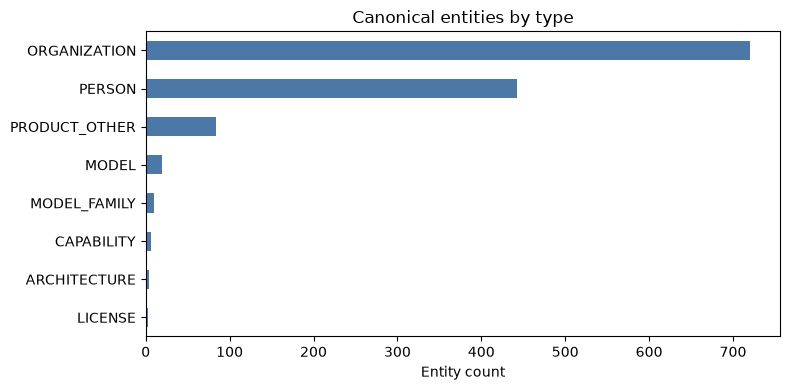

,canonical_name,entity_type,mention_count,document_count,first_seen,last_seen
305,Google,ORGANIZATION,507,146,2024-09-18,2026-08-24
426,Meta,ORGANIZATION,565,110,2024-09-18,2026-08-11
329,Hugging Face,ORGANIZATION,165,93,2024-09-18,2026-08-24
37,Llama,MODEL_FAMILY,915,88,2024-09-12,2026-08-11
429,Microsoft,ORGANIZATION,287,77,2024-09-18,2026-07-24
48,AI,ORGANIZATION,110,74,2024-09-26,2026-08-11
5,Long Context,CAPABILITY,135,64,2024-09-18,2026-08-24
1,Mixture of Experts,ARCHITECTURE,90,52,2024-10-23,2026-08-11
41,Qwen,MODEL_FAMILY,221,51,2024-11-03,2026-08-24
73,Alibaba,ORGANIZATION,124,49,2024-11-13,2026-08-11


In [5]:
entities = pd.read_parquet(OUTPUT_DIR / "entities.parquet")
relations = pd.read_parquet(OUTPUT_DIR / "relations.parquet")
cooccurrence = pd.read_parquet(OUTPUT_DIR / "cooccurrence_edges.parquet")

entity_type_counts = entities["entity_type"].value_counts().sort_values()
ax = entity_type_counts.plot.barh(figsize=(8, 4), color="#4C78A8")
ax.set(title="Canonical entities by type", xlabel="Entity count", ylabel="")
plt.tight_layout()
plt.show()

entities.sort_values(["document_count", "mention_count"], ascending=False).head(20)[
    ["canonical_name", "entity_type", "mention_count", "document_count", "first_seen", "last_seen"]
]

Generic `PERSON`, `ORGANIZATION`, and `PRODUCT_OTHER` nodes come from statistical
NER and are retained only in sentences that also contain a domain entity. Curated model,
family, licence, architecture, and capability entities use stable IDs.

## Typed relations with evidence

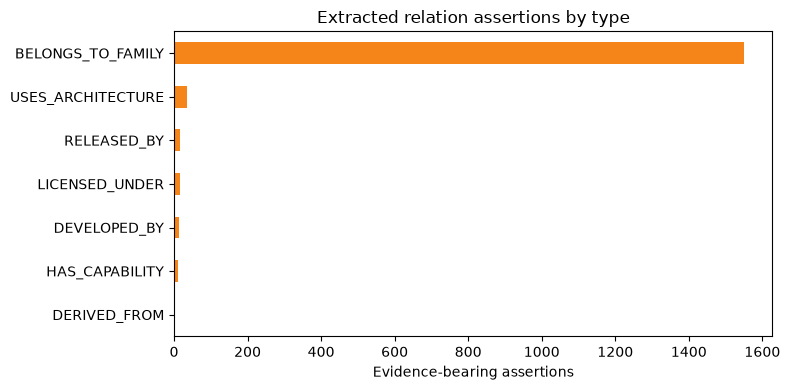

,subject_label,predicate,object_label,assertion_status,rule_score,evidence_text
1009,DeepSeek-R1,DERIVED_FROM,DeepSeek-V3,asserted,0.80,\nWhile DeepSeek V3 wasn’ t popular immediatel...
799,Mistral,LICENSED_UNDER,Apache License 2.0,asserted,0.90,\nIn a move that developers and the broader AI...
1547,Llama,DEVELOPED_BY,Meta,asserted,0.85,Llama is a collection of open models developed...
500,DeepSeek-R1,USES_ARCHITECTURE,Mixture of Experts,asserted,0.70,\nBased on the recently introduced DeepSeek V3...
1269,Gemma,DEVELOPED_BY,Google,asserted,0.85,\nGemma is a family of open models built by Go...
1315,Gemma 4,HAS_CAPABILITY,Long Context,asserted,0.65,"\nGemma 4 E2B supports a 128K context window, ..."
1048,Mixtral 8x22B,USES_ARCHITECTURE,Mixture of Experts,asserted,0.70,They feature the innovative Mixture of Experts...
811,Mistral,LICENSED_UNDER,Apache License 2.0,asserted,0.90,"\nVoxtral, which Mistral will release under an..."
316,Llama 3.2,RELEASED_BY,Meta,asserted,0.85,"\nAmong others, Meta AI released their latest ..."
14,Llama 3.2,USES_ARCHITECTURE,Transformer,asserted,0.70,\nModel Architecture: Llama 3.2 is an auto-reg...


In [6]:
relation_type_counts = relations["predicate"].value_counts().sort_values()
ax = relation_type_counts.plot.barh(figsize=(8, 4), color="#F58518")
ax.set(title="Extracted relation assertions by type", xlabel="Evidence-bearing assertions", ylabel="")
plt.tight_layout()
plt.show()

labels = entities.set_index("entity_id")["canonical_name"]
relation_view = relations.assign(
    subject_label=relations["subject_id"].map(labels),
    object_label=relations["object_id"].map(labels),
)
relation_view[relation_view["predicate"] != "BELONGS_TO_FAMILY"].sample(
    min(20, (relation_view["predicate"] != "BELONGS_TO_FAMILY").sum()), random_state=42
)[["subject_label", "predicate", "object_label", "assertion_status", "rule_score", "evidence_text"]]

## Entity co-occurrence

In [7]:
cooccurrence_view = cooccurrence.assign(
    source_label=cooccurrence["source_id"].map(labels),
    target_label=cooccurrence["target_id"].map(labels),
)
cooccurrence_view.sort_values(
    ["document_count", "sentence_count"], ascending=False
).head(25)[
    ["source_label", "target_label", "sentence_count", "document_count", "first_seen", "last_seen"]
]

,source_label,target_label,sentence_count,document_count,first_seen,last_seen
0,Llama,Meta,190,52,2024-09-18,2026-08-11
1,Google,Microsoft,41,30,2024-09-18,2026-07-23
2,Gemma,Google,53,28,2024-12-02,2026-07-14
3,Google,Meta,26,25,2024-10-04,2026-04-30
4,AI,Google,21,21,2024-11-01,2026-07-14
5,Qwen,Alibaba,32,19,2025-03-05,2026-07-23
6,Google,OpenAI,20,19,2024-10-04,2026-08-11
7,Gemini,Google,19,19,2025-03-01,2026-07-14
8,AI,Meta,22,17,2024-09-26,2026-08-11
9,Amazon,Microsoft,22,17,2024-09-18,2026-07-10


## Manual review protocol

Open `relation_review_sample.csv` and label `review_correct` as `TRUE`, `FALSE`, or
`AMBIGUOUS` using the quoted evidence sentence and linked source. Rejected rows also require
`review_error_type`. At least two team members should independently review disagreements.
Report precision by predicate; do not call coverage “recall” without an annotated gold set.

In [8]:
review = pd.read_csv(OUTPUT_DIR / "relation_review_sample.csv")
review[[
    "subject_label", "predicate", "object_label", "evidence_text", "title", "url",
    "review_correct", "reviewer", "review_error_type", "review_notes",
]].head(10)

,subject_label,predicate,object_label,evidence_text,title,url,review_correct,reviewer,review_error_type,review_notes
0,DeepSeek-R1,BELONGS_TO_FAMILY,DeepSeek,"👇\nBut for me, Deepseek R1 model feels like a ...",🔥 Gemma 3 27B vs. QwQ 32B vs. Deepseek R1 comp...,https://dev.to/composiodev/gemma-3-27b-vs-qwq-...,NaN,NaN,NaN,NaN
1,Qwen3,BELONGS_TO_FAMILY,Qwen,\nQwen3.6 does not officially support the soft...,DavidAU/Qwen3.6-27B-Fable-Fusion-711-Uncensore...,https://www.huggingface.co/DavidAU/Qwen3.6-27B...,NaN,NaN,NaN,NaN
2,Llama 3.3,BELONGS_TO_FAMILY,Llama,The Llama 3.3 Community License allows for the...,meta-llama/Llama-3.3-70B-Instruct · Hugging Face,https://huggingface.co/meta-llama/Llama-3.3-70...,NaN,NaN,NaN,NaN
3,Llama 3.3,BELONGS_TO_FAMILY,Llama,Use in any other way that is prohibited by the...,meta-llama/Llama-3.3-70B-Instruct · Hugging Face,https://huggingface.co/meta-llama/Llama-3.3-70...,NaN,NaN,NaN,NaN
4,DeepSeek-R1,BELONGS_TO_FAMILY,DeepSeek,"But as with DeepSeek-R1, the fact that the mod...",Alibaba’ s new open source model QwQ-32B match...,https://venturebeat.com/ai/alibabas-new-open-s...,NaN,NaN,NaN,NaN
5,Llama 3.3,BELONGS_TO_FAMILY,Llama,Developers may fine-tune Llama 3.3 models for ...,meta-llama/Llama-3.3-70B-Instruct · Hugging Face,https://huggingface.co/meta-llama/Llama-3.3-70...,NaN,NaN,NaN,NaN
6,Llama 3.3,BELONGS_TO_FAMILY,Llama,The Llama 3.3 model also supports the ability ...,meta-llama/Llama-3.3-70B-Instruct · Hugging Face,https://huggingface.co/meta-llama/Llama-3.3-70...,NaN,NaN,NaN,NaN
7,Llama 3,BELONGS_TO_FAMILY,Llama,"For Llama 3, we conducted new in-depth session...",QuantFactory/Llama-3.2-1B-GGUF · Hugging Face,https://huggingface.co/QuantFactory/Llama-3.2-...,NaN,NaN,NaN,NaN
8,Llama 3.2,BELONGS_TO_FAMILY,Llama,Learn More\nTogether AI has made a splash in t...,Here’ s how to try Meta’ s new Llama 3.2 with ...,https://venturebeat.com/ai/heres-how-to-try-me...,NaN,NaN,NaN,NaN
9,Gemma 4,BELONGS_TO_FAMILY,Gemma,\nWhen we kicked off the Gemma 4 Good Challeng...,A look at the winning entries from the Gemma 4...,https://blog.google/innovation-and-ai/technolo...,NaN,NaN,NaN,NaN


## WP3 handoff

- `entities.parquet` and `relations.parquet` are the canonical graph tables.
- `knowledge_graph.graphml` is a visualization-friendly export.
- `knowledge_graph.json` is a NetworkX node-link export for programmatic loading.
- `schema.json` defines allowed edge signatures.
- `DATA_DICTIONARY.md`, `qa_report.json`, and `run_manifest.json` document semantics,
  integrity checks, configuration, versions, and input provenance.

For Stage 3, retrieve text evidence by `document_id`/`text_unit_id`; graph triples alone
should not be presented as sufficient evidence.